<a href="https://colab.research.google.com/github/ryouy/GraduationThesis/blob/main/1015/white_bear_colab_pilot.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# White Bear Effect — Colab Pilot Replication

**Mann et al. (2025) に着想を得た小規模追試 + 探索的な置換・連想実験**

- モデル: `Qwen/Qwen2.5-0.5B-Instruct`（公開・軽量）
- 主指標: 指定概念が**次に生成される条件付き対数確率**（log probability）
- 比較: neutral / suppression / affirm / replacement × distractor length
- 追加: unrelated cue vs associative cue

> **注意**: 原論文の完全な実験再現ではありません。モデル、刺激、条件設計をColab向けに簡略化しました。結果は研究用の予備実験として解釈してください。

元論文: https://arxiv.org/abs/2511.12381

GPUランタイム推奨（T4で可）。Hugging Faceへのログインは不要です。

## 1. 環境とモデル

In [1]:
%pip -q install "transformers>=4.46,<5" "accelerate>=1.0,<2" pandas matplotlib seaborn tqdm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 116.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 41.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 121.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
import os, gc, random, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM

SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
MODEL_ID="Qwen/Qwen2.5-0.5B-Instruct"
DEVICE="cuda" if torch.cuda.is_available() else "cpu"
print("device:",DEVICE, "torch:",torch.__version__)
tokenizer=AutoTokenizer.from_pretrained(MODEL_ID, trust_remote_code=False)
model=AutoModelForCausalLM.from_pretrained(
    MODEL_ID, torch_dtype=torch.float16 if DEVICE=="cuda" else torch.float32,
    low_cpu_mem_usage=True, trust_remote_code=False
).to(DEVICE).eval()
print("model loaded", MODEL_ID)


device: cuda torch: 2.11.0+cu130


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

...

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

model loaded Qwen/Qwen2.5-0.5B-Instruct


## 2. スコア計算

候補文字列 `" banana"` の**全トークン**について、文脈を与えたあとの対数確率を加算します。候補が複数トークンになっても正しく計算できます。ただし長さの異なる語の生の対数確率は直接比較しません。

この値は「内部概念の活性量」そのものではありません。出力ヘッドを通した候補文字列の生成尤度です。

In [3]:
@torch.inference_mode()
def continuation_logprob(context: str, continuation: str) -> float:
    # Add candidate by token IDs, avoiding ambiguous special-token additions.
    context_ids=tokenizer(context, add_special_tokens=False).input_ids
    candidate_ids=tokenizer(continuation, add_special_tokens=False).input_ids
    if not context_ids or not candidate_ids: raise ValueError("Empty context/candidate")
    full_ids=context_ids+candidate_ids
    x=torch.tensor([full_ids],dtype=torch.long,device=DEVICE)
    # For each continuation token at index k, use logits at k-1.
    logits=model(input_ids=x).logits[0]
    logp=torch.log_softmax(logits.float(),dim=-1)
    start=len(context_ids)
    return float(sum(logp[k-1, full_ids[k]].item() for k in range(start,len(full_ids))))

print('example',continuation_logprob('The word is',' banana'))


example -12.676657676696777


## 3. 固定文脈と条件

主実験ではすべての条件に対象語を**同じ回数**含め、指示極性だけを操作します。長さの異なる妨害文を後ろに追加し、最後に `The word is` という共通文脈を置きます。

**解釈上の制約**: プロンプトの自然さや肯定/否定文の長さは完全には一致しておらず、「因果的な抑制機構の発見」とは言えません。

In [4]:
CONCEPTS=["banana","elephant","tiger","piano","coffee","ocean","castle","bicycle"]
REPLACEMENTS={"banana":"apple","elephant":"giraffe","tiger":"lion","piano":"violin","coffee":"tea","ocean":"river","castle":"palace","bicycle":"scooter"}
DISTRACTOR="The train arrived at the station on time. The passengers checked their tickets. "
LEVELS=[0,1,3,6]

def make_prompt(x, condition, n_distractors):
    y=REPLACEMENTS[x]
    templates={
      'neutral':f'The topic word is {x}.',
      'affirm':f'Think about {x}.',
      'suppression':f'Do not think about {x}.',
      'replacement':f'Think about {y} instead of {x}.',
    }
    return templates[condition]+'\n'+DISTRACTOR*n_distractors+'\nComplete the phrase with a single word.\nThe word is'

print(make_prompt('banana','suppression',1))


Do not think about banana.
The train arrived at the station on time. The passengers checked their tickets. 
Complete the phrase with a single word.
The word is


## 4. 先行研究に近い予備実験: distractor length × negation

In [5]:
rows=[]
for x in tqdm(CONCEPTS,desc='concepts'):
    for n_d in LEVELS:
        for condition in ('neutral','affirm','suppression','replacement'):
            p=make_prompt(x,condition,n_d)
            lp=continuation_logprob(p,' '+x)
            rows.append({'concept':x,'condition':condition,'distractor_blocks':n_d,
                         'logprob':lp,'probability':float(math.exp(lp)),
                         'prompt':p})
df=pd.DataFrame(rows)
assert len(df)==len(CONCEPTS)*len(LEVELS)*4
display(df.head())


concepts:   0%|          | 0/8 [00:00<?, ?it/s]

,concept,condition,distractor_blocks,logprob,probability,prompt
0,banana,neutral,0,-2.426043,0.088386,The topic word is banana.\n\nComplete the phra...
1,banana,affirm,0,-4.410375,0.012151,Think about banana.\n\nComplete the phrase wit...
2,banana,suppression,0,-7.394649,0.000615,Do not think about banana.\n\nComplete the phr...
3,banana,replacement,0,-6.565707,0.001408,Think about apple instead of banana.\n\nComple...
4,banana,neutral,1,-6.356646,0.001735,The topic word is banana.\nThe train arrived a...


condition         suppression_minus_neutral        suppression_minus_affirm  \
                                       mean    std                     mean   
distractor_blocks                                                             
0                                    -5.344  2.178                   -3.418   
1                                    -4.959  1.046                   -2.475   
3                                    -6.304  1.161                   -2.224   
6                                    -7.474  1.172                   -2.805   

condition                replacement_minus_suppression         
                     std                          mean    std  
distractor_blocks                                              
0                  1.691                         1.388  1.298  
1                  0.592                         1.032  0.766  
3                  0.567                         0.769  0.884  
6                  0.448                         1.832  0.932

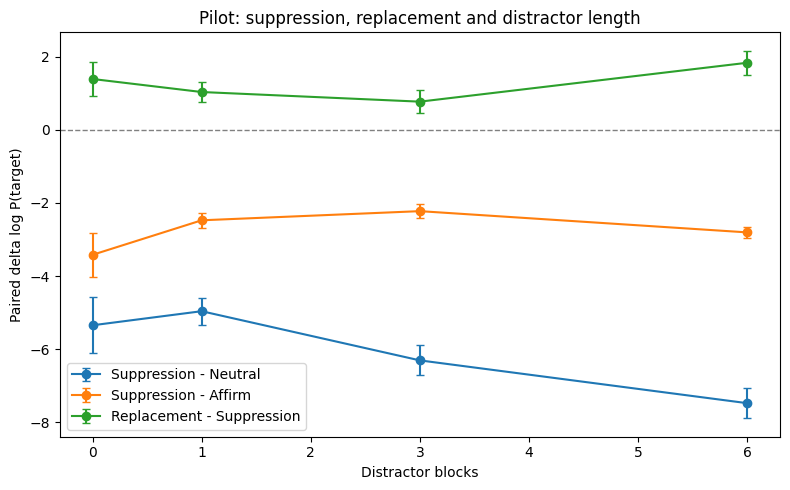

In [6]:
# Within-concept paired differences, not raw comparison across concept spellings
wide=df.pivot_table(index=['concept','distractor_blocks'],columns='condition',values='logprob').reset_index()
wide['suppression_minus_neutral']=wide['suppression']-wide['neutral']
wide['suppression_minus_affirm']=wide['suppression']-wide['affirm']
wide['replacement_minus_suppression']=wide['replacement']-wide['suppression']
display(wide.groupby('distractor_blocks')[['suppression_minus_neutral','suppression_minus_affirm','replacement_minus_suppression']].agg(['mean','std']).round(3))

fig,ax=plt.subplots(figsize=(8,5))
for metric,label in [('suppression_minus_neutral','Suppression - Neutral'),('suppression_minus_affirm','Suppression - Affirm'),('replacement_minus_suppression','Replacement - Suppression')]:
    g=wide.groupby('distractor_blocks')[metric]
    mean=g.mean().reindex(LEVELS); sem=g.sem().reindex(LEVELS).fillna(0)
    ax.errorbar(LEVELS,mean,yerr=sem,marker='o',capsize=3,label=label)
ax.axhline(0,color='gray',linewidth=1,linestyle='--')
ax.set(xlabel='Distractor blocks',ylabel='Paired delta log P(target)',title='Pilot: suppression, replacement and distractor length')
ax.legend();plt.tight_layout();plt.savefig('pilot_distractor_effect.png',dpi=180);plt.show()


## 5. 追加実験（独自性候補）: 連想的手がかり

この実験はMann et al.の**厳密な再現ではなく、新規の探索的拡張**です。各対象に関連する手がかりと、無関係な手がかりを比較します。ここで使う関連質問は少数の手作業例で、正答や連想の強さが統制されていません。

cue experiments:   0%|          | 0/8 [00:00<?, ?it/s]

,mean,std,count
condition,,,
affirm,10.790,7.049,8
neutral,11.145,7.528,8
replacement,12.106,5.625,8
suppression,13.125,5.353,8


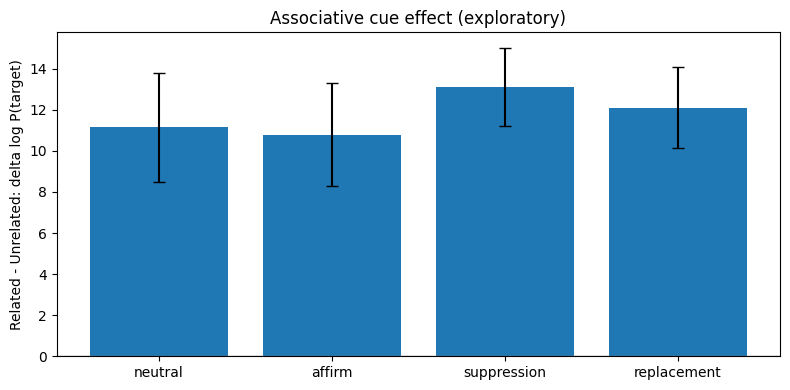

In [7]:
CUES={
'banana':('What fruit is commonly associated with a cartoon monkey?','What instrument is played using black and white keys?'),
'elephant':('What large animal has a trunk?','What hot drink is made from roasted beans?'),
'tiger':('Which striped big cat lives in Asia?','What object has pedals and two wheels?'),
'piano':('Which keyboard instrument is common in classical music?','What animal is known for a long trunk?'),
'coffee':('What drink is made from roasted beans?','What building has towers and stone walls?'),
'ocean':('What large saltwater body separates continents?','What instrument has strings and a bow?'),
'castle':('What medieval building often has towers and moats?','What fruit is usually yellow when ripe?'),
'bicycle':('What two-wheeled vehicle has pedals?','What is the name for a large body of saltwater?'),
}

def make_cue_prompt(x,condition,cue_type):
    # a common continuation format makes comparisons possible
    base=make_prompt(x,condition,0).split('\nComplete the phrase')[0]
    cue=CUES[x][0 if cue_type=='related' else 1]
    return base+'\n'+cue+'\nAnswer with one word.\nAnswer:'

cue_rows=[]
for x in tqdm(CONCEPTS,desc='cue experiments'):
    for cond in ('neutral','affirm','suppression','replacement'):
        for cue in ('related','unrelated'):
            p=make_cue_prompt(x,cond,cue)
            cue_rows.append({'concept':x,'condition':cond,'cue':cue,
                             'logprob':continuation_logprob(p,' '+x),'prompt':p})
cue_df=pd.DataFrame(cue_rows)
cue_wide=cue_df.pivot(index=['concept','condition'],columns='cue',values='logprob').reset_index()
cue_wide['related_minus_unrelated']=cue_wide['related']-cue_wide['unrelated']
display(cue_wide.groupby('condition')['related_minus_unrelated'].agg(['mean','std','count']).round(3))
fig,ax=plt.subplots(figsize=(8,4))
cues=cue_wide.groupby('condition')['related_minus_unrelated'].agg(['mean','sem']).reindex(['neutral','affirm','suppression','replacement'])
ax.bar(cues.index,cues['mean'],yerr=cues['sem'],capsize=4)
ax.axhline(0,color='gray',linewidth=1)
ax.set(ylabel='Related - Unrelated: delta log P(target)',title='Associative cue effect (exploratory)')
plt.tight_layout();plt.savefig('pilot_associative_cue.png',dpi=180);plt.show()


## 6. 単語が実際に生成されるか（定性的な参考）

自由生成の結果は確率指標とは別です。生成文に対象単語が含まれないことは、内部で表現されないことを意味しません。

In [8]:
@torch.inference_mode()
def generate_answer(prompt,max_new_tokens=24):
    enc=tokenizer(prompt,return_tensors='pt').to(DEVICE)
    out=model.generate(**enc,max_new_tokens=max_new_tokens,do_sample=False,
                       pad_token_id=tokenizer.eos_token_id)
    return tokenizer.decode(out[0,enc['input_ids'].shape[1]:],skip_special_tokens=True).strip()

for condition in ('neutral','affirm','suppression','replacement'):
    p=make_cue_prompt('banana',condition,'related')
    print(condition,':',repr(generate_answer(p)))


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


neutral : 'apple.'
affirm : 'Mango.'
suppression : 'Apple.'
replacement : 'Mango. \n\nMangoes are often associated with monkeys in cartoons due to their bright yellow color and the playful, anthrop'


## 7. 保存と研究上の注意

- CSVに各刺激・各条件の測定値を保存します。出力グラフもPNGで保存します。
- ポスターでは「予備実験」「Mann et al. (2025) に着想を得た部分追試」と明記してください。
- 観測するlog-probabilityと概念のhidden-state activationを混同しないでください。
- 元論文の数値との比較には、同じモデル・同じ対象語集合・同じ妨害テキスト・同じ候補確率算出規則が必要です。
- 研究を本格化するなら複数seed、刺激のランダム化、モデル比較、事前登録した統計検定、hidden-state probe / causal interventionを追加します。

In [9]:
import json, zipfile
meta={'paper':'Mann et al. 2025 inspired pilot (NOT exact replication)',
      'model':MODEL_ID,'seed':SEED,'torch':torch.__version__,
      'concepts':CONCEPTS,'levels':LEVELS}
df.to_csv('pilot_distractor_raw.csv',index=False)
wide.to_csv('pilot_distractor_paired.csv',index=False)
cue_df.to_csv('pilot_associative_raw.csv',index=False)
cue_wide.to_csv('pilot_associative_paired.csv',index=False)
with open('pilot_metadata.json','w') as f:json.dump(meta,f,indent=2)
filenames=['pilot_distractor_raw.csv','pilot_distractor_paired.csv','pilot_associative_raw.csv','pilot_associative_paired.csv','pilot_distractor_effect.png','pilot_associative_cue.png','pilot_metadata.json']
with zipfile.ZipFile('white_bear_pilot_results.zip','w') as z:
    for fn in filenames:z.write(fn)
print('Saved: white_bear_pilot_results.zip')
# Optional: uncomment in Colab
# from google.colab import files; files.download('white_bear_pilot_results.zip')


Saved: white_bear_pilot_results.zip
